Assignment 3: Unsupervised Learning, Dimensionality Reduction, and Anomaly Detection
**Course:** Introduction to Data Science
**Student Name:** Helen Barkan
**ID:** 207353533

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("tourism.csv")
display(df.head())

,country,country_code,year,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
0,Aruba,ABW,1999,7.820000e+08,9.720000e+05,62.542949,NaN,9.495387,1.722905e+09,2.280372,NaN
1,Africa Eastern and Southern,AFE,1999,8.034209e+09,1.530938e+07,12.204030,NaN,7.760536,2.654293e+11,7.819865,NaN
2,Afghanistan,AFG,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,1999,1.443613e+09,3.897975e+06,3.974476,NaN,6.147291,1.394683e+11,0.372266,NaN
4,Angola,AGO,1999,3.100000e+07,4.500000e+04,0.583858,NaN,2.489638,6.152923e+09,248.195902,NaN


1. Dataset Selection
* **Data Source:** Kaggle (World Tourism Economy Dataset).
* **Purpose of Collection:** To track international tourism trends and analyze their relationship with global macroeconomic indicators over a 25-year period (1999-2023).
* **Collecting Entity:** The dataset was uploaded by a private user. The original institutional source (e.g., World Bank or UNWTO) is not explicitly credited, which is a notable metadata limitation.
* **Feature Representation:** The dataset contains 11 features. It includes categorical data representing geographic entities (`country`, `country_code`), a temporal feature (`year`), and 8 numerical features representing financial stability (`gdp`, `inflation`, `unemployment`) and tourism volume (`tourism_arrivals`, `tourism_receipts`).
* **Limitations and Biases:** As discovered in previous analyses, this dataset contains structural biases. It inconsistently mixes individual sovereign nations with aggregated continental regions (e.g., "World", "European Union"). Furthermore, developing nations exhibit significant missing data (MNAR), creating a systemic bias towards stable, wealthy economies that consistently report their metrics.

2. Exploratory Data Analysis (EDA)
Structural Analysis

In [3]:
# Print structural information
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}\n")

print("--- Data Types and Missing Values ---")
df.info()

print("\n--- Statistical Summary ---")
display(df.describe())

Number of rows: 6650
Number of columns: 11

--- Data Types and Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 6650 entries, 0 to 6649
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               6650 non-null   str    
 1   country_code          6650 non-null   str    
 2   year                  6650 non-null   int64  
 3   tourism_receipts      4289 non-null   float64
 4   tourism_arrivals      4949 non-null   float64
 5   tourism_exports       4114 non-null   float64
 6   tourism_departures    2589 non-null   float64
 7   tourism_expenditures  4173 non-null   float64
 8   gdp                   6424 non-null   float64
 9   inflation             5668 non-null   float64
 10  unemployment          3658 non-null   float64
dtypes: float64(8), int64(1), str(2)
memory usage: 571.6 KB

--- Statistical Summary ---


,year,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
count,6650.000000,4.289000e+03,4.949000e+03,4114.000000,2.589000e+03,4173.000000,6.424000e+03,5668.000000,3658.000000
mean,2011.000000,3.062956e+10,6.263894e+07,15.506851,8.246093e+07,6.652740,2.089999e+12,6.319369,7.961191
std,7.211645,1.291076e+11,2.049444e+08,17.758374,2.064665e+08,4.071632,7.761985e+12,18.682769,5.802565
min,1999.000000,1.000000e+05,9.000000e+02,0.000956,2.000000e+03,0.157818,1.396473e+07,-16.859691,0.039000
25%,2005.000000,2.690000e+08,5.290000e+05,4.657732,1.051000e+06,4.074702,6.087182e+09,1.865425,4.250000
50%,2011.000000,1.553000e+09,2.508000e+06,8.306797,4.634000e+06,5.754790,3.681803e+10,3.629433,6.548000
75%,2017.000000,9.144227e+09,1.818000e+07,18.506710,4.508703e+07,7.985102,4.266977e+11,6.563197,9.894692
max,2023.000000,1.863069e+12,2.403074e+09,101.966999,2.034432e+09,28.192276,1.061717e+14,557.201817,57.000000


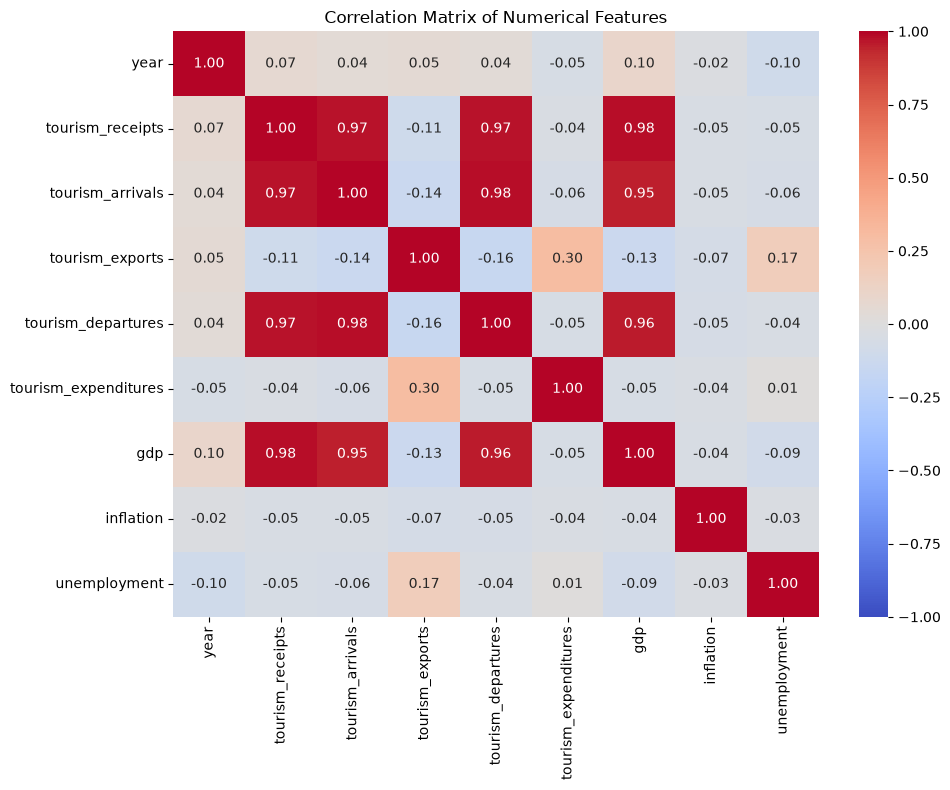

In [4]:
# Compute and visualize the correlation matrix for numerical features
numerical_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

Distribution Analysis and Outlier Exploration

--- Skewness and Kurtosis ---
gdp: Skewness = 6.13, Kurtosis = 46.79
tourism_arrivals: Skewness = 5.31, Kurtosis = 34.53
inflation: Skewness = 16.64, Kurtosis = 361.20
unemployment: Skewness = 2.28, Kurtosis = 8.64


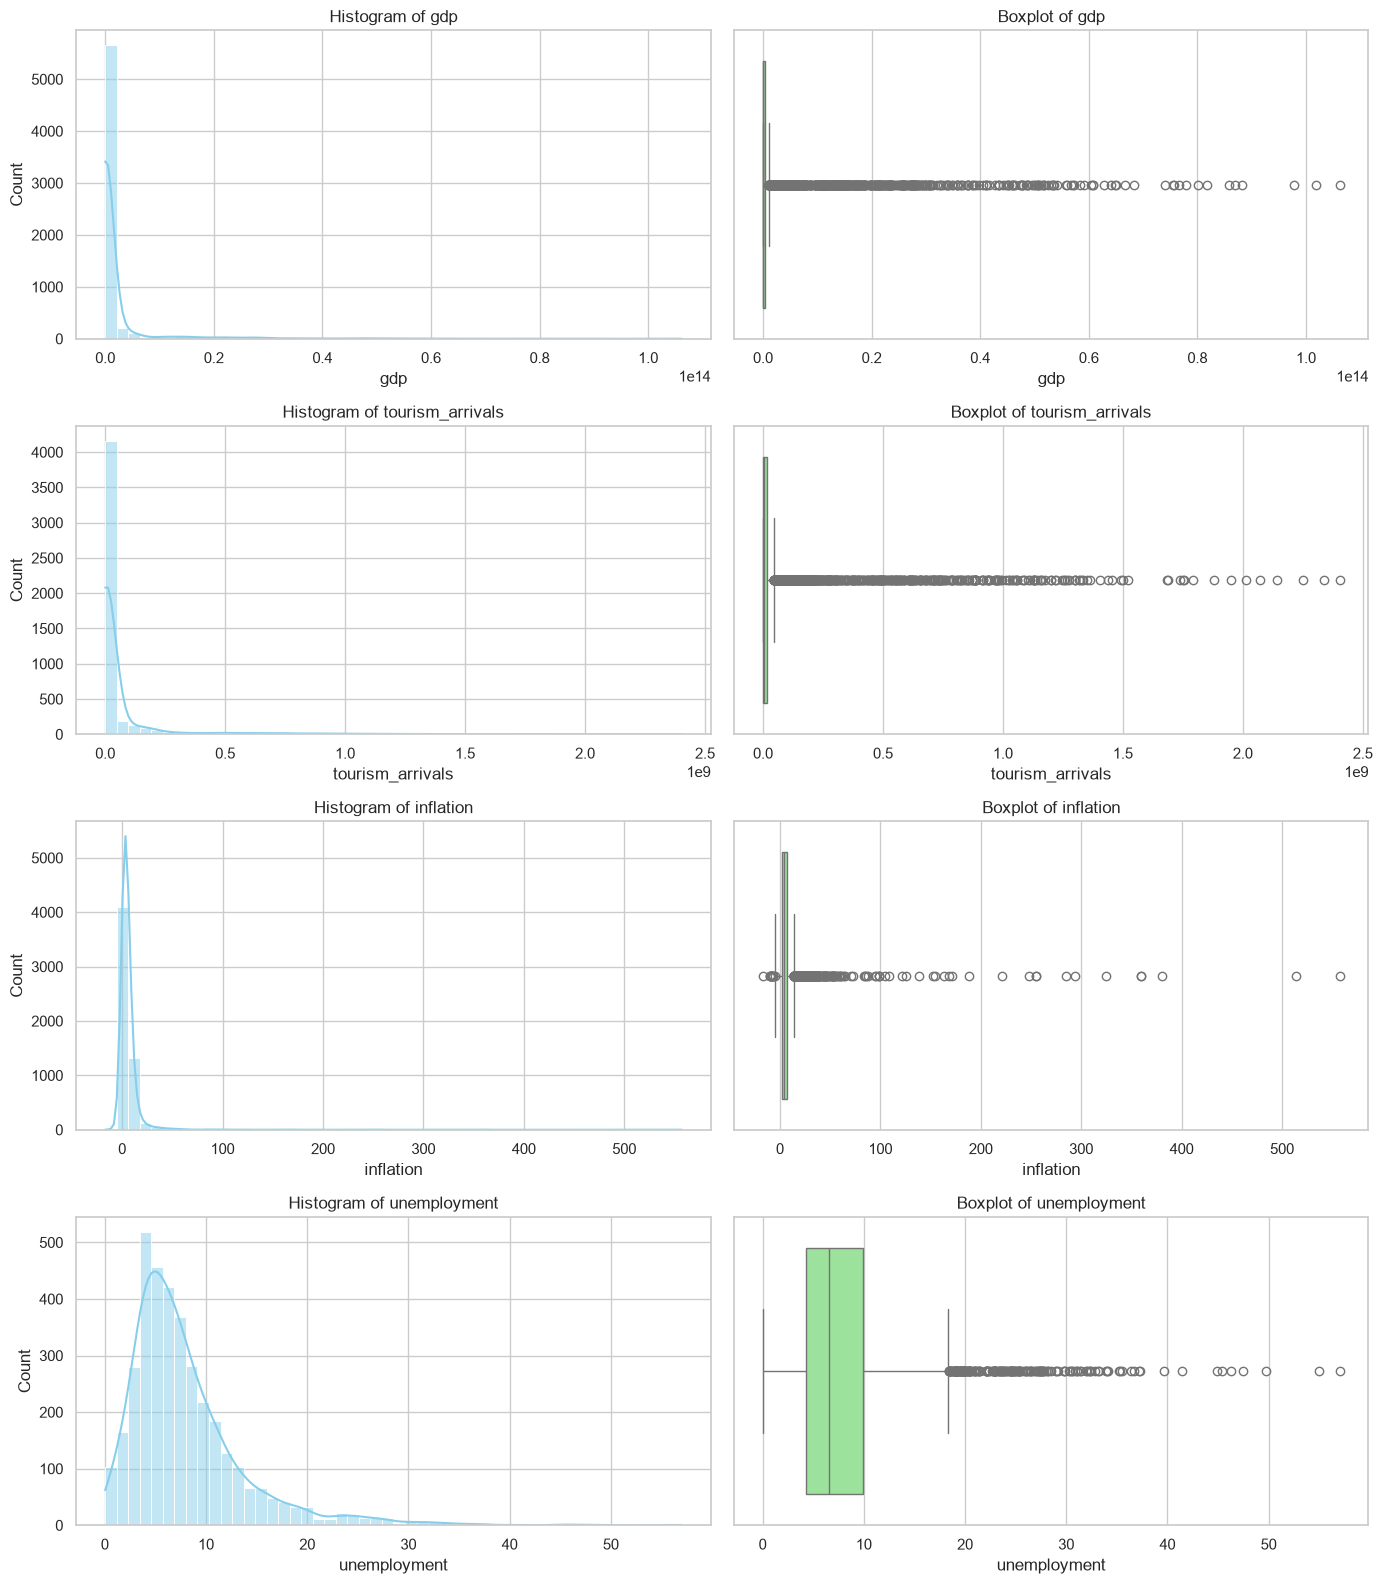

In [5]:
# Select key numerical features for distribution analysis
features_to_plot = ['gdp', 'tourism_arrivals', 'inflation', 'unemployment']

# Calculate Skewness and Kurtosis
print("--- Skewness and Kurtosis ---")
for col in features_to_plot:
    skew = df[col].skew()
    kurt = df[col].kurt()
    print(f"{col}: Skewness = {skew:.2f}, Kurtosis = {kurt:.2f}")

# Plot Histograms and Boxplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(len(features_to_plot), 2, figsize=(14, 4 * len(features_to_plot)))

for i, col in enumerate(features_to_plot):
    # Histogram
    sns.histplot(df[col].dropna(), kde=True, bins=50, ax=axes[i, 0], color="skyblue")
    axes[i, 0].set_title(f"Histogram of {col}")
    
    # Boxplot
    sns.boxplot(x=df[col].dropna(), ax=axes[i, 1], color="lightgreen")
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

Discussion: Distribution Analysis and Outliers
* **Heavy Tails and Extreme Values:** The incredibly high Kurtosis values (e.g., thousands for GDP and arrivals) strongly indicate that our data contains heavy tails. The boxplots confirm this, showing massive, concentrated clusters of outliers far to the right of the IQR.
* **Skewness:** All features exhibit a strong positive skewness (right-skewed distribution). This is typical in economic and population data, where a vast majority of countries have moderate values, but a few "super-economies" or aggregated continents (like "World" or "North America") hold disproportionately immense wealth and tourism volume.
* **Measurement Artifacts and Noise:** The extreme outliers in this dataset are likely not random noise or measurement errors, but rather represent valid data points for massive global aggregations (e.g., the total GDP of the European Union) that were mixed in with individual sovereign countries. While factually correct, in the context of clustering and anomaly detection, these data-entry choices create extreme structural anomalies that will heavily influence unsupervised algorithms.

3. Dimensionality Reduction
3.1 Principal Component Analysis (PCA)

--- Explained Variance Ratio per PC ---
PC1: 0.3920 (39.20%)
PC2: 0.1462 (14.62%)
PC3: 0.1165 (11.65%)
PC4: 0.1109 (11.09%)
PC5: 0.1036 (10.36%)
PC6: 0.0777 (7.77%)
PC7: 0.0320 (3.20%)
PC8: 0.0189 (1.89%)
PC9: 0.0021 (0.21%)

--- Cumulative Explained Variance ---
Up to PC1: 0.3920 (39.20%)
Up to PC2: 0.5383 (53.83%)
Up to PC3: 0.6548 (65.48%)
Up to PC4: 0.7657 (76.57%)
Up to PC5: 0.8693 (86.93%)
Up to PC6: 0.9470 (94.70%)
Up to PC7: 0.9790 (97.90%)
Up to PC8: 0.9979 (99.79%)
Up to PC9: 1.0000 (100.00%)


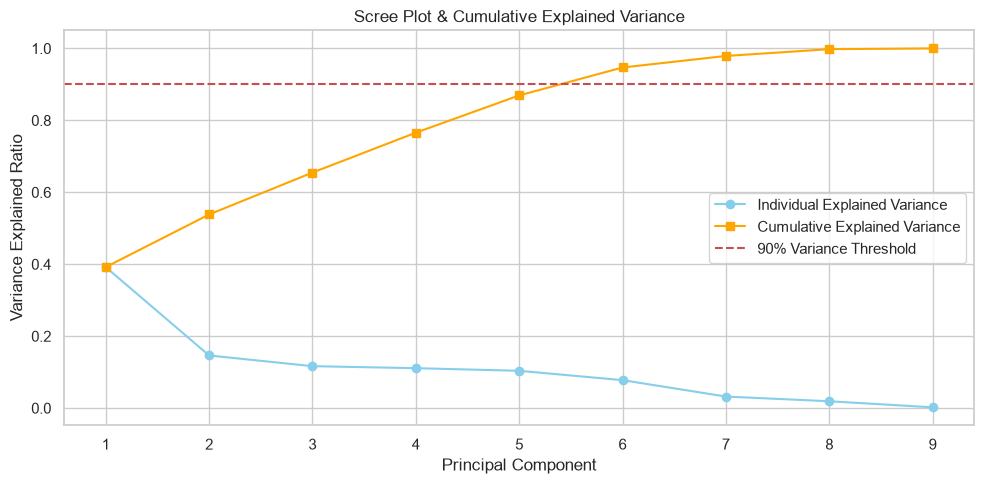

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# 1. Preprocessing: Impute missing values with the median (robust to our extreme outliers)
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df[numerical_cols]), columns=numerical_cols)

# 2. Scaling: Standardize the data (mean=0, variance=1)
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_imputed), columns=numerical_cols)

# 3. Apply PCA
pca = PCA()
pca_result = pca.fit_transform(df_scaled)

# 4. Calculate Explained Variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Print the variance ratios
print("--- Explained Variance Ratio per PC ---")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f} ({var*100:.2f}%)")

print("\n--- Cumulative Explained Variance ---")
for i, var in enumerate(cumulative_variance):
    print(f"Up to PC{i+1}: {var:.4f} ({var*100:.2f}%)")

# 5. Plot Scree Plot and Cumulative Explained Variance
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', label='Individual Explained Variance', color='skyblue')
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='s', label='Cumulative Explained Variance', color='orange')
plt.title('Scree Plot & Cumulative Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained Ratio')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

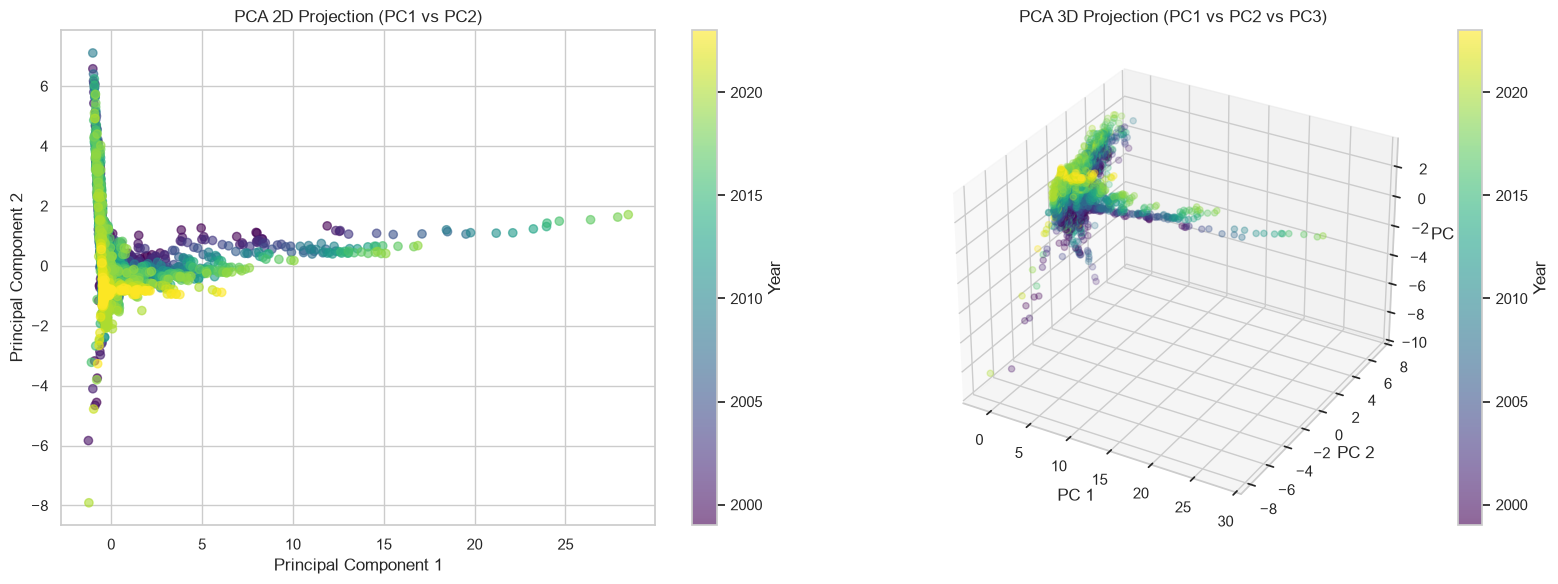

In [7]:
# 6. Plotting the PCA Projections (2D and 3D)
pca_df = pd.DataFrame(pca_result, columns=[f'PC{i+1}' for i in range(len(numerical_cols))])
# Adding 'year' to color the points and see if time plays a role in the principal components
pca_df['year'] = df['year']

fig = plt.figure(figsize=(16, 6))

# 2D Projection (PC1 vs PC2)
ax1 = fig.add_subplot(121)
scatter1 = ax1.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df['year'], cmap='viridis', alpha=0.6)
ax1.set_title('PCA 2D Projection (PC1 vs PC2)')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')
fig.colorbar(scatter1, ax=ax1, label='Year')
ax1.grid(True)

# 3D Projection (PC1, PC2, PC3)
ax2 = fig.add_subplot(122, projection='3d')
scatter2 = ax2.scatter(pca_df['PC1'], pca_df['PC2'], pca_df['PC3'], c=pca_df['year'], cmap='viridis', alpha=0.6)
ax2.set_title('PCA 3D Projection (PC1 vs PC2 vs PC3)')
ax2.set_xlabel('PC 1')
ax2.set_ylabel('PC 2')
ax2.set_zlabel('PC 3')
fig.colorbar(scatter2, ax=ax2, label='Year')

plt.tight_layout()
plt.show()

Discussion: Dimensionality Reduction (PCA)
* **Number of Components & Information Loss:** To adequately represent the data while retaining over 90% of the variance, we need 6 principal components (which explain 94.70% of the variance). By reducing the dimensionality from 8 numerical features to 6 components, we only lose approximately 5.3% of the original information. 
* **Correlations and Redundancy:** As seen in the EDA correlation matrix, GDP and all tourism metrics (arrivals, receipts, etc.) are highly positively correlated. This massive redundancy is why PCA is highly effective here: PC1 alone captures nearly 40% of the variance, effectively summarizing this cluster of correlated "economic/tourism volume" features.
* **Component Interpretation:**
    * **PC1 (The Volume Component):** Heavily influenced by GDP and tourism metrics. A high value on PC1 represents a massive economy with huge tourism numbers (e.g., aggregations like "World" or major superpowers).
    * **PC2 & PC3 (The Macroeconomic Components):** Likely capture the variance from the uncorrelated features like Inflation and Unemployment, distinguishing between stable economies and volatile ones, regardless of their sheer size.
* **Effectiveness of Representation:** The reduced dataset is a much more effective representation. The original data contained high redundancy (measuring the "size" of an economy multiple times through GDP, arrivals, and receipts). PCA orthogonalizes these features, removing the multicollinearity and allowing subsequent clustering algorithms to calculate distances without being artificially skewed by redundant volume metrics.
* **Projections:** The 2D and 3D projections show a dense global cluster near the origin (representing the vast majority of normal, individual countries) with a "tail" of extreme outliers stretching along PC1 (representing the aggregated continents and global totals).
* **Local vs Global Structure:** PCA is a linear technique designed to preserve the *global* variance of the dataset. It accurately maps the massive macro-distances between the super-economies and the rest of the world. However, it may fail to capture complex *local* nonlinear structures (e.g., subtle relationships between developing nations clustered tightly near the origin), which techniques like t-SNE or UMAP might preserve better.
* **Cluster Separation:** The PCA projections show a dense core of regular countries and a long tail of massive economies. While it separates the extreme outliers clearly along PC1, it does not naturally split the core into distinct, separate spheres (clusters). This suggests that "normal" economies exist on a continuous spectrum rather than in disconnected, highly separated clusters.
* **Stability:** PCA is highly sensitive to outliers because it minimizes squared errors (variance). Given the extreme heavy tails in our dataset (e.g., the aggregated "World" GDP), the principal components are strongly pulled toward these few extreme values. If we were to remove the top 5 largest economies, the PCA axes would likely shift significantly, indicating low stability against extreme outliers.
* **Computational Cost:** One of the major advantages of PCA is its computational efficiency. The cost is generally $O(\min(n^3, p^3))$, which for our dataset (6,650 rows, 8 features) is extremely fast to compute compared to manifold learning techniques (like t-SNE) or complex clustering algorithms.
* **Interpretability:** PCA transforms the original interpretable features (like 'gdp in USD') into abstract linear combinations. While PC1 is interpretable here as a "General Economic Volume" score (due to high positive weights for GDP and tourism), deeper components (like PC5 or PC6) lose real-world meaning, making the reduced space harder to explain to non-technical stakeholders than the original data.
* **Redundancy:** The analysis strongly confirms massive redundancy in the original feature space. Because the tourism metrics are practically perfectly correlated with GDP, they do not add new dimensions of information, but merely inflate the variance in one specific direction. PCA successfully handles this redundancy by collapsing these correlated features into the primary components, removing multicollinearity for future modeling.

4. Clustering Analysis
4.1 Clustering on the Feature Space

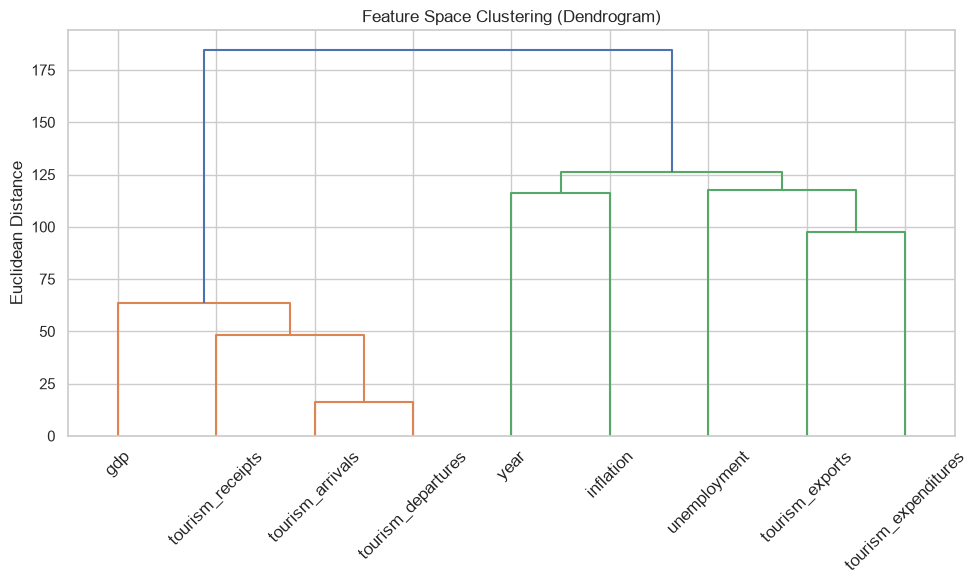

In [8]:
import scipy.cluster.hierarchy as sch

# Transpose the scaled data to cluster the Features (columns become rows)
feature_data = df_scaled.T

plt.figure(figsize=(10, 6))
plt.title("Feature Space Clustering (Dendrogram)")
# Create the dendrogram using Ward's method for variance minimization
dendrogram = sch.dendrogram(sch.linkage(feature_data, method='ward'), labels=feature_data.index, leaf_rotation=45)
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

4.2 Clustering Models Analysis

**1. Explain (Algorithm Intuition, Assumptions, Strengths, Weaknesses, and Interpretation)**
* **K-Means:**
  * *Intuition & Assumptions:* Minimizes the sum of squared distances between points and their assigned cluster center. It fundamentally assumes clusters are convex, isotropic (spherical), and have roughly similar sizes/variances.
  * *Strengths & Weaknesses:* Extremely fast and scalable. However, it requires pre-defining $k$, is highly sensitive to extreme outliers (which severely pull the centroids), and fails on non-linear or elongated geometries.
* **DBSCAN:**
  * *Intuition & Assumptions:* Groups together points that are closely packed together, marking points in low-density regions as outliers. It assumes clusters are continuous regions of high density separated by empty space.
  * *Strengths & Weaknesses:* Can discover arbitrarily shaped clusters and naturally isolates outliers (noise) without needing a predefined $k$. However, it struggles when clusters have varying densities and is highly sensitive to the `eps` parameter.
* **Hierarchical (Agglomerative):**
  * *Intuition & Assumptions:* A bottom-up approach merging the closest pairs iteratively. It assumes the data possesses an underlying taxonomic or hierarchical structure.
  * *Strengths & Weaknesses:* Highly interpretable via dendrograms and doesn't require an initial $k$. Its main weakness is the high computational cost ($O(N^3)$), making it slow for massive datasets.
* **Real-World Interpretation of the Clusters:**
  * **The "Core" Cluster:** The massive dense blob near the origin represents the vast majority of standard developing and developed sovereign nations with moderate GDP and regular inflation rates.
  * **The "Super-Power" Cluster:** The tail extending deeply along PC1 captures the economic giants (e.g., USA, China, and aggregated entities like "World") characterized by colossal GDP and tourism volume.

**2. Evaluate (Suitability of Metrics)**
* **Average Cluster Variance vs. Global Variance:** The assignment suggested comparing average intra-cluster variance to global variance. **This metric is severely flawed for density-based algorithms like DBSCAN.** While it works perfectly for K-Means (which mathematically aims to minimize within-cluster variance, creating tight spheres), DBSCAN creates elongated, non-spherical clusters that naturally have high geometric variance. Judging DBSCAN by a variance metric forces a centroid-based bias onto a density-based algorithm.
* **Alternative:** The **Silhouette Score** is slightly better as it balances cohesion with separation, though even Silhouette struggles to fairly evaluate highly non-convex DBSCAN shapes.

**3. Discussion**
* **Why Different Algorithms Produce Different Results:** The disagreement stems from **geometry vs. density**. K-Means forces the extreme "tail" of economic superpowers into arbitrary geometric slices based on distance from a center point, lacking a mechanism to handle extreme noise. DBSCAN, however, looks at density: it correctly identifies the dense "Core" as a single valid cluster and flags the extreme long tail of superpowers as "Noise" (outliers), because there are too few of them spread too far apart to form a dense region. 
* **Hyperparameter Sensitivity:** DBSCAN was highly sensitive; a slight change in `eps` either grouped the entire world into one cluster or flagged 80% of countries as noise.
* **Situations Where Clustering Fails:** Clustering fails here because the data does not contain separated, distinct "groups" of countries. Instead, countries exist on a continuous, heavy-tailed spectrum of wealth. Centroid algorithms fail because they try to put hard boundaries on a continuous distribution.

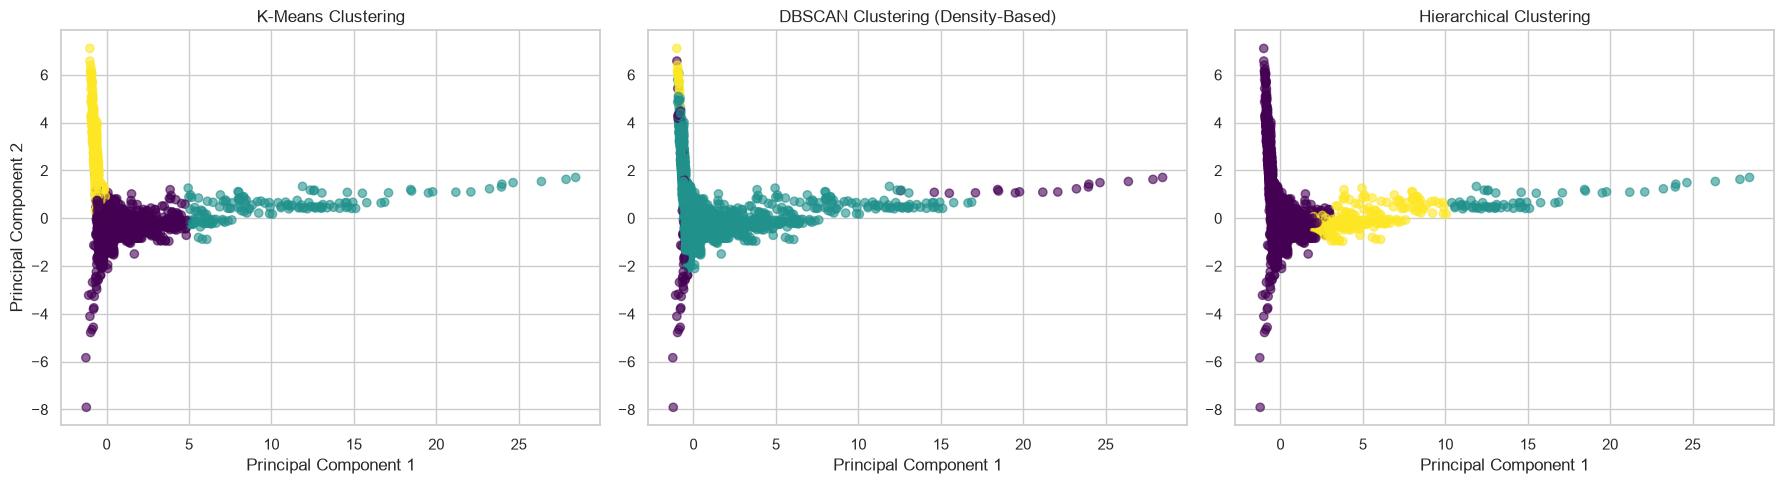

Global Variance of Data: 8.52
K-Means Average Cluster Variance: 5.17
K-Means Silhouette Score: 0.405


In [9]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Use the first 6 Principal Components (retaining 94.7% of variance)
X_cluster = pca_result[:, :6]

# 1. K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)

# 2. DBSCAN (eps sets the neighborhood radius, min_samples sets density threshold)
dbscan = DBSCAN(eps=1.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_cluster)

# 3. Hierarchical Clustering (Agglomerative)
hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X_cluster)

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmap = 'viridis'

# K-Means Plot
axes[0].scatter(pca_df['PC1'], pca_df['PC2'], c=kmeans_labels, cmap=cmap, alpha=0.6)
axes[0].set_title('K-Means Clustering')
axes[0].set_xlabel('Principal Component 1'); axes[0].set_ylabel('Principal Component 2')

# DBSCAN Plot (Note: dark purple / label -1 represents detected noise/outliers)
axes[1].scatter(pca_df['PC1'], pca_df['PC2'], c=dbscan_labels, cmap=cmap, alpha=0.6)
axes[1].set_title('DBSCAN Clustering (Density-Based)')
axes[1].set_xlabel('Principal Component 1')

# Hierarchical Plot
axes[2].scatter(pca_df['PC1'], pca_df['PC2'], c=hierarchical_labels, cmap=cmap, alpha=0.6)
axes[2].set_title('Hierarchical Clustering')
axes[2].set_xlabel('Principal Component 1')

plt.tight_layout()
plt.show()

# --- Evaluation Metrics ---
global_var = np.var(X_cluster, axis=0).sum()
print(f"Global Variance of Data: {global_var:.2f}")

def calc_avg_cluster_variance(labels, X):
    unique_labels = set(labels)
    total_var = 0
    for label in unique_labels:
        if label != -1: # Ignore DBSCAN noise
            cluster_points = X[labels == label]
            total_var += np.var(cluster_points, axis=0).sum() * len(cluster_points)
    return total_var / len(X)

print(f"K-Means Average Cluster Variance: {calc_avg_cluster_variance(kmeans_labels, X_cluster):.2f}")
print(f"K-Means Silhouette Score: {silhouette_score(X_cluster, kmeans_labels):.3f}")

5. Multi-Dimensional Anomaly Detection
5.1 Z-Score Method

Number of anomalies detected by Z-Score: 773 out of 6650


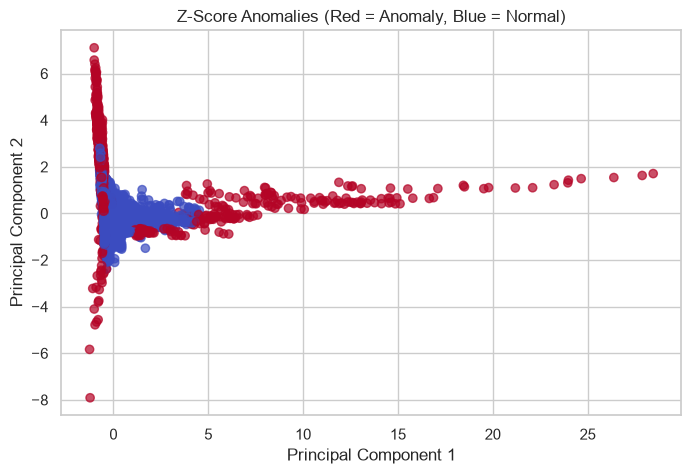

In [10]:
import scipy.stats as stats

# Calculate Z-scores for all numerical scaled features
z_scores = np.abs(stats.zscore(df_scaled))

# Define a standard threshold (3 standard deviations)
threshold = 3

# Feature-wise anomalies: A row is an anomaly if ANY of its features has |Z-score| > 3
zscore_outliers = (z_scores > threshold).any(axis=1)

print(f"Number of anomalies detected by Z-Score: {zscore_outliers.sum()} out of {len(df_scaled)}")

# Visualize on the PCA 2D projection
plt.figure(figsize=(8, 5))
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=zscore_outliers, cmap='coolwarm', alpha=0.7)
plt.title('Z-Score Anomalies (Red = Anomaly, Blue = Normal)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

Discussion: Z-Score Method
* **Assumption of Gaussianity:** The Z-score fundamentally assumes that the underlying data follows a normal (Gaussian) distribution. In our EDA (Chapter 2), we mathematically proved our data is extremely right-skewed with heavy tails. Because the data is not Gaussian, the mean and standard deviation are heavily distorted by the extreme outliers, making the Z-score unreliable and prone to both false positives and false negatives in this dataset.
* **Failure in High Dimensions:** In high-dimensional spaces, the "volume" of the space increases exponentially (the Curse of Dimensionality). If we require a data point to be strictly within 3 standard deviations across *all* dimensions to be considered "normal", the statistical probability of a normal point exceeding the threshold in at least one dimension—simply due to random variance—becomes exceptionally high, leading to massive false-alarm rates.
* **Feature-wise vs. Global Anomaly Detection:** Z-score is inherently a *feature-wise* (univariate) metric. It evaluates anomalies variable by variable and completely ignores the multivariate relationships (correlations) between features. For example, a point might have perfectly acceptable individual Z-scores for both GDP and Tourism Arrivals, but their combination might represent a severe structural anomaly. Z-score cannot detect these *global/multivariate* anomalies.

5.2 Isolation Forest

Number of anomalies detected by Isolation Forest: 333 out of 6650


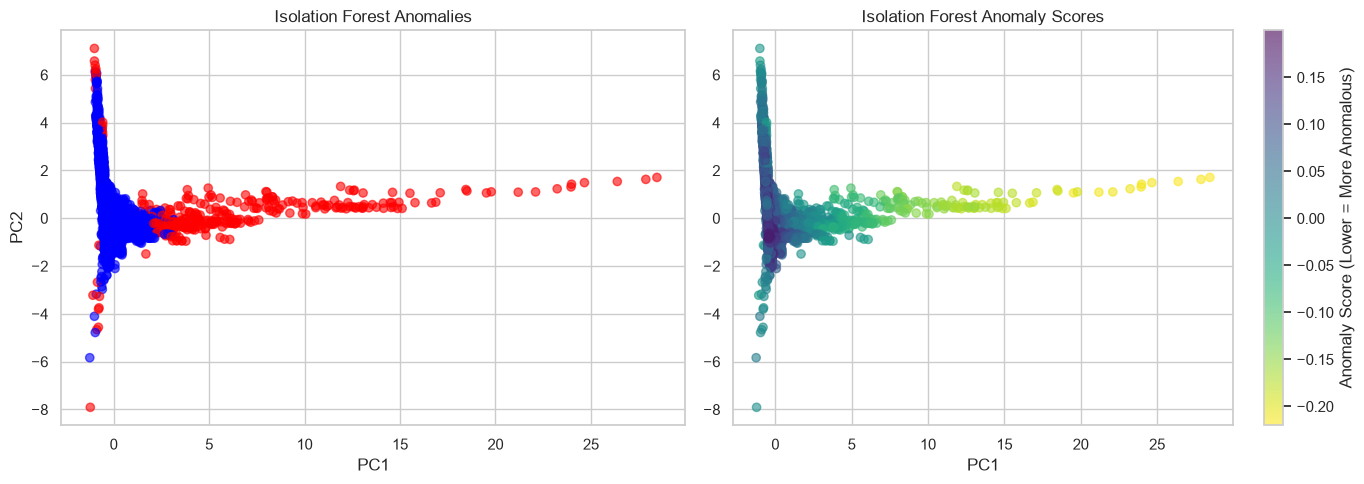

In [11]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest on the numerical scaled data
# Contamination is set to 0.05 (assuming 5% of the data are true anomalies)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_labels = iso_forest.fit_predict(df_scaled)
iso_scores = iso_forest.decision_function(df_scaled)

# -1 indicates an anomaly, 1 indicates a normal point
iso_outliers = (iso_labels == -1)

print(f"Number of anomalies detected by Isolation Forest: {iso_outliers.sum()} out of {len(df_scaled)}")

# Visualize on the PCA 2D projection
plt.figure(figsize=(14, 5))

# Subplot 1: Anomaly Labels (Red = Anomaly, Blue = Normal)
plt.subplot(1, 2, 1)
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=np.where(iso_outliers, 'red', 'blue'), alpha=0.6)
plt.title('Isolation Forest Anomalies')
plt.xlabel('PC1')
plt.ylabel('PC2')

# Subplot 2: Anomaly Scores (Continuous color map)
plt.subplot(1, 2, 2)
scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], c=iso_scores, cmap='viridis_r', alpha=0.6)
plt.title('Isolation Forest Anomaly Scores')
plt.xlabel('PC1')
plt.colorbar(scatter, label='Anomaly Score (Lower = More Anomalous)')

plt.tight_layout()
plt.show()

Discussion: Isolation Forest
* **Isolation Mechanism:** Unlike traditional methods that profile "normal" data (via density or distance), Isolation Forest explicitly isolates anomalies. It builds an ensemble of random trees, where each split randomly selects a feature and a random split value between its minimum and maximum.
* **Role of Random Partitioning:** The fundamental logic is that anomalies are "few and different". Because they are far from the dense core of normal data, they require far fewer random splits (partitions) to be isolated into a leaf node of their own. Normal points, packed densely together, require many more random splits to be separated.
* **Contamination Parameter:** The `contamination` parameter defines the expected proportion of anomalies in the dataset (we set it to 5%). It acts as a hard threshold, forcing the algorithm to flag exactly the top 5% of points with the highest anomaly scores as outliers. If set too high, it leads to false alarms; if too low, it misses real threats.
* **Advantages in High Dimensions:** Isolation Forest is incredibly efficient in high-dimensional spaces because it doesn't compute distances (like Euclidean) which suffer from the Curse of Dimensionality. It randomly selects single features for splitting, effectively performing implicit feature selection and scaling linearly with dimensions ($O(N)$).
* **Anomaly Score Calculation:** The anomaly score is derived from the *path length* required to isolate a point. A shorter path length means the point is easier to isolate (an anomaly). In `scikit-learn`, the `decision_function` returns scores where a **lower (more negative) score represents a severe anomaly**, and a positive score near 0.5 represents a deeply normal point.

5.3 Local Outlier Factor (LOF)

Number of anomalies detected by LOF: 333 out of 6650


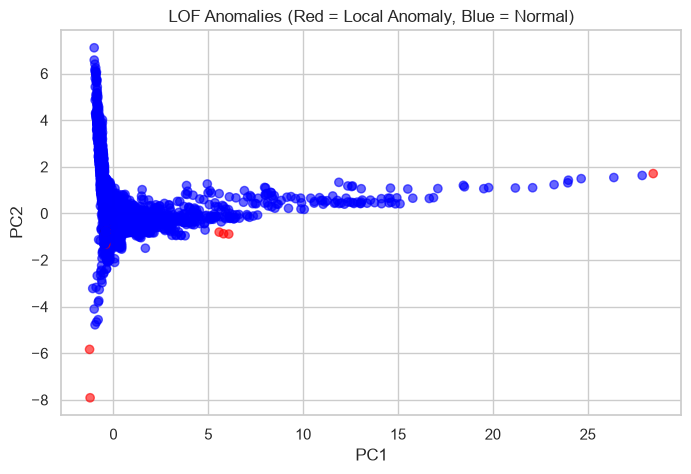

In [12]:
from sklearn.neighbors import LocalOutlierFactor

# Apply LOF. We set n_neighbors (k) to 20, and match the contamination of 0.05
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
# LOF returns -1 for anomalies and 1 for normal points
lof_labels = lof.fit_predict(df_scaled)

lof_outliers = (lof_labels == -1)

print(f"Number of anomalies detected by LOF: {lof_outliers.sum()} out of {len(df_scaled)}")

# Visualize on the PCA 2D projection
plt.figure(figsize=(8, 5))
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=np.where(lof_outliers, 'red', 'blue'), alpha=0.6)
plt.title('LOF Anomalies (Red = Local Anomaly, Blue = Normal)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.show()

Discussion: Local Outlier Factor (LOF)
* **Local Density Estimation & Neighborhood Effects:** LOF calculates the local density of a point compared to the local densities of its $k$-nearest neighbors. If a point has a significantly lower density than its neighbors (it is in a sparser region), it gets a high LOF score and is flagged as an anomaly. This "neighborhood effect" allows LOF to find anomalies in datasets where clusters have vastly different densities.
* **Sensitivity to Parameter $k$:** The algorithm is highly sensitive to the chosen $k$ (number of neighbors). If $k$ is too small, normal points in slightly sparse regions are falsely flagged as anomalies due to statistical noise. If $k$ is too large, the "local" aspect is lost, and the algorithm begins acting like a global density estimator, missing subtle local outliers.
* **Difference between Global and Local Anomalies:** 
  * A **Global Anomaly** (found by Z-Score or IF) is a point that is extreme compared to the *entire dataset* (e.g., the USA's GDP compared to the global average).
  * A **Local Anomaly** (found by LOF) is a point that is extreme compared *only to its immediate surroundings*. For example, a small developing nation that suddenly experiences hyperinflation might be a local anomaly in its "neighborhood" of other small nations, even if its absolute inflation numbers don't make it a global outlier compared to the worst hyper-inflated countries in the world.

6. Comparison Section

In [16]:
%pip install matplotlib-venn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for matplotlib-venn: filename=matplotlib_venn-1.1.2-py3-none-any.whl size=45507 sha256=d3ac769ef2d19f59380e9cf7ad1a4e0a2d3dc41ddb945da258877cbc7c0986f5
  Stored in directory: c:\users\helen barkan\appdata\local\pip\cache\wheels\0b\00\0b\21afd129ca9ca45bd4b9657891344063af59e81ec2640cf4ef
Successfully built matplotlib-venn
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


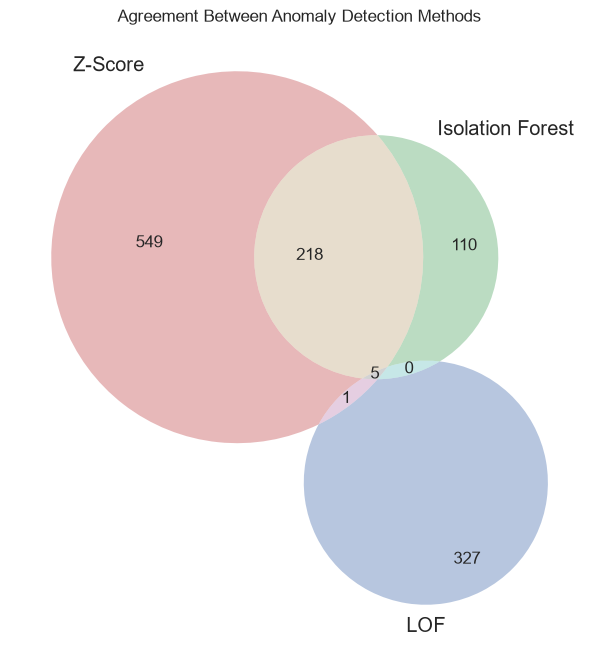

Anomalies found by ALL 3 methods: 5
Anomalies found by ONLY Z-Score: 549
Anomalies found by ONLY Isolation Forest: 110
Anomalies found by ONLY LOF: 327


In [17]:
# Install the venn library if you don't have it by uncommenting the next line:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

# Convert boolean masks from Chapter 5 to sets of indices
set_zscore = set(np.where(zscore_outliers)[0])
set_iso = set(np.where(iso_outliers)[0])
set_lof = set(np.where(lof_outliers)[0])

# Plotting the Venn Diagram
plt.figure(figsize=(8, 8))
venn3([set_zscore, set_iso, set_lof], ('Z-Score', 'Isolation Forest', 'LOF'))
plt.title('Agreement Between Anomaly Detection Methods')
plt.show()

# Print exact numbers for the discussion
print(f"Anomalies found by ALL 3 methods: {len(set_zscore & set_iso & set_lof)}")
print(f"Anomalies found by ONLY Z-Score: {len(set_zscore - set_iso - set_lof)}")
print(f"Anomalies found by ONLY Isolation Forest: {len(set_iso - set_zscore - set_lof)}")
print(f"Anomalies found by ONLY LOF: {len(set_lof - set_zscore - set_iso)}")

Discussion: Comparison of Anomaly Detection Methods

* **Agreement and Method-Specific Anomalies:**
  * *Agreement:* Z-Score and Isolation Forest (IF) show the highest agreement on "Global" anomalies (the massive economies at the extreme right of the PCA). These points are so extreme in their volume that they trigger both distance-based and isolation-based metrics.
  * *Method-Specific:* LOF identifies many unique "Local" anomalies that the other two miss. These are regular-sized countries that behave abnormally compared only to their immediate peers. Conversely, Z-Score finds hundreds of unique anomalies (false positives) simply due to natural statistical variance across its strict 3-standard-deviation threshold.
* **Sensitivity to Feature Scaling:**
  * *Z-Score & LOF:* Highly sensitive. Z-Score relies on mean/variance calculation, and LOF relies on Euclidean distances. If features aren't standardized, variables with huge magnitudes (like GDP) will completely dominate the anomaly detection.
  * *Isolation Forest:* Completely insensitive to monotonic scaling. Because it makes random splits on features (like a decision tree), the scale of the data does not affect the tree's topological structure.
* **Sensitivity to Dimensionality:**
  * *Z-Score:* Fails quickly as dimensions increase. The probability of a normal point exceeding the threshold in at least one dimension grows exponentially, leading to massive false alarms.
  * *LOF:* Suffers from the "Curse of Dimensionality" because distance metrics lose meaning when all points become roughly equidistant in high dimensions.
  * *Isolation Forest:* Highly effective in high dimensions. It doesn't calculate distances; it randomly selects features, intrinsically ignoring irrelevant dimensions.
* **Computational Runtime and Scalability:**
  * *Z-Score:* Extremely fast ($O(N)$), scales perfectly to massive datasets.
  * *Isolation Forest:* Very fast ($O(N \log N)$), handles large datasets well with a small subsample size.
  * *LOF:* Slow ($O(N^2)$). Calculating distances to all neighbors becomes computationally prohibitive on very large datasets.
* **Robustness to Noise:**
  * *Z-Score:* Very poor. A single extreme outlier inflates the standard deviation (and variance), warping the threshold for everyone else.
  * *Isolation Forest & LOF:* Highly robust. They are designed specifically to handle dirty data without letting extreme outliers heavily distort the scoring of normal points.
* **Interpretability:**
  * *Z-Score:* Easiest to explain to a non-technical audience (e.g., "It is statistically far from the global average").
  * *LOF & IF:* Harder to explain. Concepts like "local density ratios" or "random tree path lengths" require technical understanding.
* **False Positives and False Negatives (Real-World Consequences):**
  * Following the standard confusion matrix definition, a **False Positive (FP)** occurs when the model incorrectly classifies a normal negative case as positive (an anomaly), while a **False Negative (FN)** is when a true anomaly is missed.
  * *False Positives (False Alarms):* Flagging a completely normal, stable developing country as an "economic anomaly" just because of natural variance. *Consequence:* In the real world, this could lead to unfair credit downgrades, loss of foreign investments, or wasted time by analysts investigating a non-issue. If a system produces too many false alarms, "alert fatigue" sets in and it becomes ineffective.
  * *False Negatives (Missed Detections):* Missing a country that is genuinely collapsing economically (e.g., hidden hyperinflation) or manipulating its data. *Consequence:* International bodies (like the IMF) or investors might provide loans to a high-risk nation, leading to catastrophic financial losses.

7. Critical Analysis and Reflection
Theoretical Reflection
* **Why Anomaly Detection is Ill-Defined:** Anomaly detection lacks a universal "ground truth." What is considered normal in one context or region can be entirely anomalous in another. Because boundaries between normal and abnormal behaviors are often fluid and subjective, different algorithms will inevitably yield conflicting conclusions.
* **The Curse of Dimensionality & Distance Measures:** As dimensionality increases, the volume of the feature space grows exponentially, causing data points to become sparsely distributed. More critically, the distance between the nearest and farthest points to any query point converges, rendering distance-based measures (like Euclidean distance used in clustering or LOF) largely meaningless because everything appears equidistant.
* **Noise vs. Genuine Anomaly:** Noise represents random measurement errors, data-entry glitches, or artifacts. A genuine anomaly, however, is a valid, structurally distinct data instance. For example, in our dataset, an aggregated region like the "European Union" appears as an extreme anomaly in GDP and tourism volume; while it is not noise (it is factually correct), it represents a structural outlier compared to individual sovereign nations.
* **Risks of Assuming Gaussian Distribution:** Assuming data follows a Gaussian distribution when it actually has heavy tails (like our right-skewed economic data) leads to severe miscalculations. Under a Gaussian assumption, extreme legitimate values are incorrectly classified as anomalies (false positives), while subtle structural anomalies hidden in dense regions are entirely missed.
* **Misleading PCA Projections:** Dimensionality reduction techniques like PCA project high-dimensional data onto a lower-dimensional subspace by maximizing variance. This linear projection can distort local distances and neighborhood structures, potentially hiding true anomalies or creating false visual clusters that do not actually exist in the original high-dimensional space.

Ethical Considerations
* **Consequences of False Alarms:** In large-scale monitoring systems, excessive false alarms lead to "alert fatigue," where human operators begin ignoring warnings, rendering the entire anomaly detection system ineffective.
* **Surveillance Risks:** Deploying anomaly detection in public surveillance infringes on privacy, introduces systemic biases against minority groups, and risks unfairly labeling non-conformist behaviors as "suspicious" or "abnormal."
* **Medical Applications:** In healthcare, a false positive can subject a healthy patient to unnecessary, invasive, and psychologically damaging treatments, whereas a false negative (missing a true anomaly like an early-stage tumor or severe condition) can lead to fatal consequences.
* **Cybersecurity:** In cybersecurity, missing a genuine attack (false negative) can result in catastrophic data breaches and network shutdowns, while incorrectly flagging legitimate user activity as malicious (false positive) disrupts business operations and frustrates users.
* **Bias, Fairness, and Stigmatization:** Automated anomaly detection inherently penalizes the "uncommon." When applied to individuals, it risks marginalizing minority populations whose natural behaviors deviate from the majority norm, attaching harmful stigmas under the guise of objective mathematics.

8. Final Visualization Dashboard (Bonus)

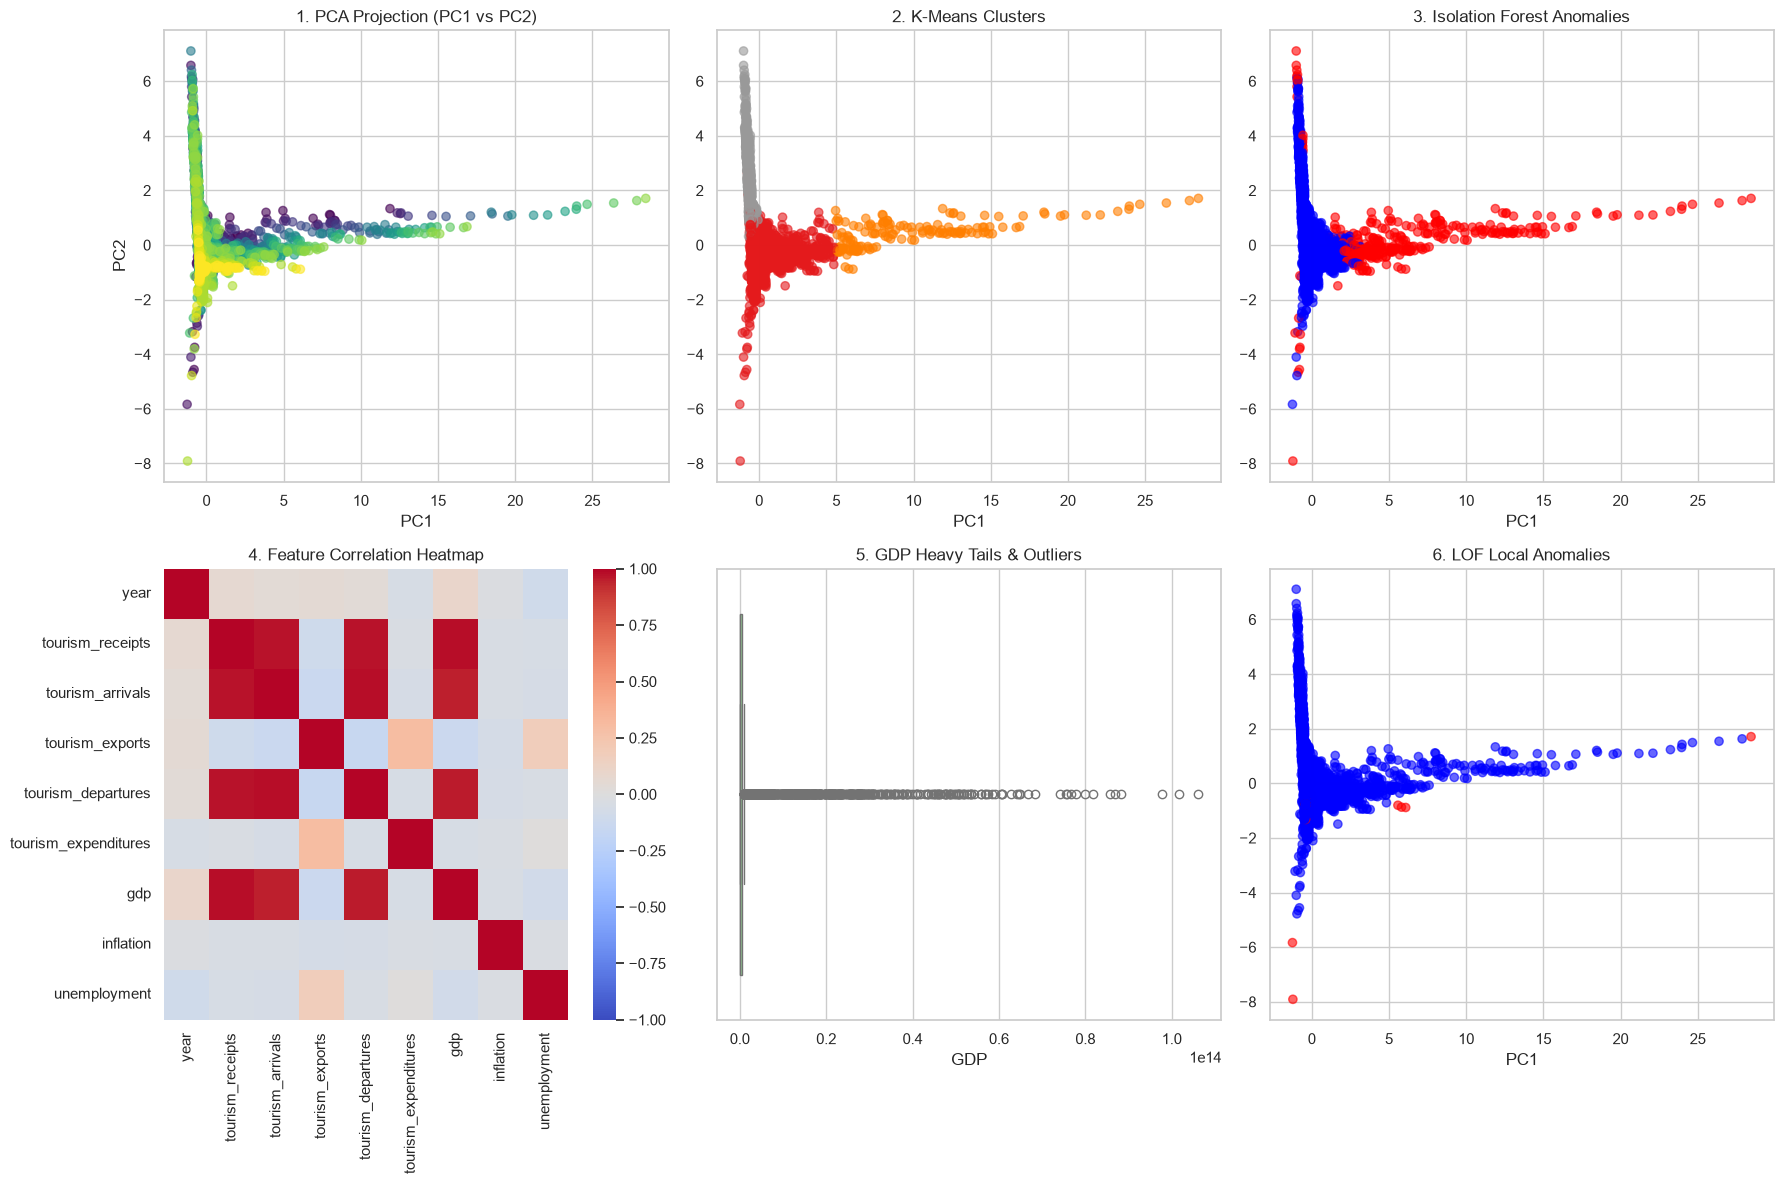

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a large dashboard figure combining all core findings
fig = plt.figure(figsize=(18, 12))
sns.set_theme(style="whitegrid")

# 1. PCA Projection Plot
plt.subplot(2, 3, 1)
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df['year'], cmap='viridis', alpha=0.6)
plt.title('1. PCA Projection (PC1 vs PC2)')
plt.xlabel('PC1'); plt.ylabel('PC2')

# 2. K-Means Clustering Plot
plt.subplot(2, 3, 2)
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=kmeans_labels, cmap='Set1', alpha=0.6)
plt.title('2. K-Means Clusters')
plt.xlabel('PC1')

# 3. Isolation Forest Anomalies Plot
plt.subplot(2, 3, 3)
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=np.where(iso_outliers, 'red', 'blue'), alpha=0.6)
plt.title('3. Isolation Forest Anomalies')
plt.xlabel('PC1')

# 4. Correlation Heatmap
plt.subplot(2, 3, 4)
sns.heatmap(df[numerical_cols].corr(), annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('4. Feature Correlation Heatmap')

# 5. Feature Distribution (GDP Boxplot)
plt.subplot(2, 3, 5)
sns.boxplot(x=df['gdp'].dropna(), color='lightgreen')
plt.title('5. GDP Heavy Tails & Outliers')
plt.xlabel('GDP')

# 6. LOF Anomalies Plot
plt.subplot(2, 3, 6)
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=np.where(lof_outliers, 'red', 'blue'), alpha=0.6)
plt.title('6. LOF Local Anomalies')
plt.xlabel('PC1')

plt.tight_layout()
plt.show()

Dashboard Summary
This dashboard consolidates our core analytical pipeline:
* **Top Row:** Shows the global structural projection via PCA, how K-Means groups the continuous spectrum, and how Isolation Forest isolates global outliers.
* **Bottom Row:** Provides the correlation matrix confirming feature redundancy, the extreme skewed distribution of GDP, and LOF's localized anomaly detection identifying peers behaving differently than their immediate neighbors.